In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)


from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE


df = pd.read_csv("../data/raw/cs-training.csv")

df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed:")]

target = "SeriousDlqin2yrs"

X = df.drop(columns=target)
y = df[target]

print("Dataset:", X.shape)
print("\nTarget distribution:")
print(y.value_counts(normalize=True).mul(100).round(2))


Dataset: (150000, 10)

Target distribution:
SeriousDlqin2yrs
0    93.32
1     6.68
Name: proportion, dtype: float64


In [8]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (105000, 10)
Validation: (22500, 10)
Test: (22500, 10)


In [ ]:
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import PowerTransformer
from sklearn.base import clone
from sklearn.metrics import average_precision_score

In [22]:

preprocessing = [
    ("imputer", SimpleImputer(strategy="median")),
    ("transformer", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", RobustScaler())
]


models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )
}

sampling_methods = {
    "Baseline": "passthrough",
    "Random Oversampling": RandomOverSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42)
}

results = []
trained_models = {}

for model_name, estimator in models.items():
    for sampling_name, sampler in sampling_methods.items():

        pipeline = ImbPipeline(
            preprocessing + [
                ("sampler", sampler),
                ("model", clone(estimator))
            ]
        )
        print(f"training {model_name}, {sampling_name}")
        pipeline.fit(X_train, y_train)

        pred = pipeline.predict(X_val)
        prob = pipeline.predict_proba(X_val)[:, 1]

        results.append({
            "Model": model_name,
            "Sampling": sampling_name,
            "accuracy": accuracy_score(y_val, pred),
            "Precision": precision_score(
                y_val, pred, zero_division=0
            ),
            "Recall": recall_score(
                y_val, pred, zero_division=0
            ),
            "F1": f1_score(y_val, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_val, prob),
            "PR-AUC": average_precision_score(y_val, prob)
        })

        trained_models[(model_name, sampling_name)] = pipeline

results_df = pd.DataFrame(results).sort_values(
    "PR-AUC", ascending=False
)

display(results_df.round(4))

training Logistic Regression, Baseline
training Logistic Regression, Random Oversampling
training Logistic Regression, SMOTE
training Decision Tree, Baseline
training Decision Tree, Random Oversampling
training Decision Tree, SMOTE
training Random Forest, Baseline
training Random Forest, Random Oversampling
training Random Forest, SMOTE


,Model,Sampling,accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
2,Logistic Regression,SMOTE,0.8268,0.2370,0.7168,0.3562,0.8581,0.3753
1,Logistic Regression,Random Oversampling,0.7997,0.2155,0.7560,0.3354,0.8565,0.3728
0,Logistic Regression,Baseline,0.9359,0.5906,0.1343,0.2189,0.8516,0.3645
6,Random Forest,Baseline,0.9361,0.5648,0.1941,0.2890,0.8476,0.3556
7,Random Forest,Random Oversampling,0.9316,0.4786,0.2606,0.3375,0.8398,0.3288
8,Random Forest,SMOTE,0.9307,0.4652,0.2487,0.3241,0.8349,0.3240
3,Decision Tree,Baseline,0.8984,0.2511,0.2626,0.2567,0.6052,0.1161
4,Decision Tree,Random Oversampling,0.9025,0.2601,0.2487,0.2542,0.5990,0.1146
5,Decision Tree,SMOTE,0.8852,0.2206,0.2832,0.2480,0.6066,0.1107


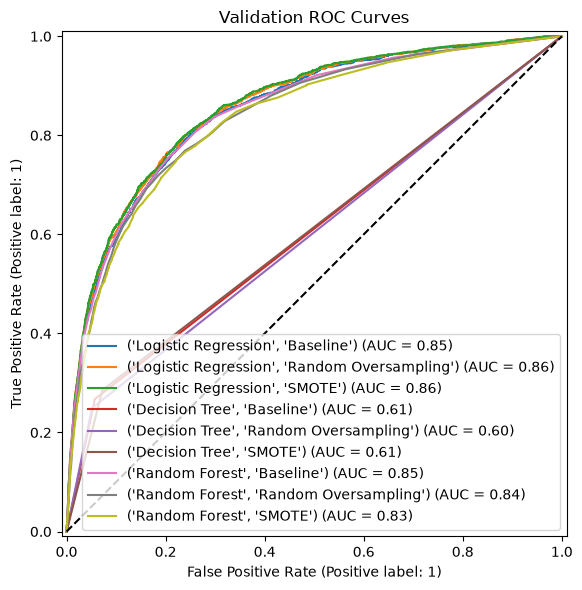

In [19]:

plt.figure(figsize=(8, 6))

for name, model in trained_models.items():
    RocCurveDisplay.from_estimator(
        model, X_val, y_val, name=name, ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], "k--")
plt.title("Validation ROC Curves")
plt.tight_layout()
plt.show()


In [30]:

best_per_model = (
    results_df
    .sort_values("PR-AUC", ascending=False)
    .groupby("Model", sort=False)
    .head(1)
    .sort_values("Model")
    .reset_index(drop=True)
)

display(best_per_model.round(4))



,Model,Sampling,accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Decision Tree,Baseline,0.8984,0.2511,0.2626,0.2567,0.6052,0.1161
1,Logistic Regression,SMOTE,0.8268,0.2370,0.7168,0.3562,0.8581,0.3753
2,Random Forest,Baseline,0.9361,0.5648,0.1941,0.2890,0.8476,0.3556


In [31]:

best_models = {}

for _, row in best_per_model.iterrows():
    name = row["Model"]
    sampling = row["Sampling"]

    best_models[name] = trained_models[(name, sampling)]

    print(f"{name}: best sampling = {sampling}")


Decision Tree: best sampling = Baseline
Logistic Regression: best sampling = SMOTE
Random Forest: best sampling = Baseline


In [32]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

test_results = []

for name, model in best_models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Sampling": best_per_model.loc[
            best_per_model["Model"] == name, "Sampling"
        ].iloc[0],
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob)
    })

test_results_df = pd.DataFrame(test_results)
display(test_results_df.round(4))


,Model,Sampling,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Decision Tree,Baseline,0.8967,0.2472,0.2666,0.2566,0.6049,0.1153
1,Logistic Regression,SMOTE,0.8270,0.2331,0.6935,0.3489,0.8517,0.3670
2,Random Forest,Baseline,0.9351,0.5458,0.1742,0.2641,0.8342,0.3569


In [33]:

from pathlib import Path
import joblib

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "Random Forest": "random_forest.joblib"
}

for name, model in best_models.items():
    path = model_dir / filenames[name]
    joblib.dump(model, path)
    print(f"Saved {name} to {path}")


Saved Decision Tree to ../models/decision_tree.joblib
Saved Logistic Regression to ../models/logistic_regression.joblib
Saved Random Forest to ../models/random_forest.joblib


In [ ]:
import optuna
from sklearn.base import clone
from sklearn.metrics import average_precision_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

best_sampling = best_per_model.set_index("Model")["Sampling"].to_dict()

def objective_factory(model_name):

    def objective(trial):

        if model_name == "Logistic Regression":
            estimator = LogisticRegression(
                C=trial.suggest_float("C", 1e-3, 100, log=True),
                class_weight=trial.suggest_categorical(
                    "class_weight", [None, "balanced"]
                ),
                max_iter=2000,
                random_state=42
            )

        elif model_name == "Decision Tree":
            estimator = DecisionTreeClassifier(
                max_depth=trial.suggest_categorical(
                    "max_depth", [None, 5, 10, 15, 20, 30]
                ),
                min_samples_split=trial.suggest_int(
                    "min_samples_split", 2, 50
                ),
                min_samples_leaf=trial.suggest_int(
                    "min_samples_leaf", 1, 30
                ),
                max_features=trial.suggest_categorical(
                    "max_features", [None, "sqrt", "log2"]
                ),
                random_state=42
            )

        else:  
            estimator = RandomForestClassifier(
                n_estimators=trial.suggest_int(
                    "n_estimators", 80, 150, step=10
                ),
                max_depth=trial.suggest_categorical(
                    "max_depth", [None, 8, 12, 16, 20, 25]
                ),
                min_samples_split=trial.suggest_int(
                    "min_samples_split", 2, 30
                ),
                min_samples_leaf=trial.suggest_int(
                    "min_samples_leaf", 1, 15
                ),
                max_features=trial.suggest_categorical(
                    "max_features", ["sqrt", "log2", None]
                ),
                random_state=42,
                n_jobs=-1
            )

        sampling_name = best_sampling[model_name]
        sampler = sampling_methods[sampling_name]

        pipeline = ImbPipeline(
            [
                (name, clone(step))
                for name, step in preprocessing
            ]
            + [
                (
                    "sampler",
                    clone(sampler) if sampler != "passthrough"
                    else "passthrough"
                ),
                ("model", estimator)
            ]
        )

        pipeline.fit(X_train, y_train)

        probabilities = pipeline.predict_proba(X_val)[:, 1]

        return average_precision_score(y_val, probabilities)

    return objective

/home/archit/Documents/CodeAlphaInternship/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [36]:
studies = {}

for model_name in models:

    print(f"\nOptimizing {model_name}...")

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42)
    )

    study.optimize(
        objective_factory(model_name),
        n_trials=10
    )

    studies[model_name] = study

    print("Best PR-AUC:", round(study.best_value, 4))
    print("Best parameters:", study.best_params)


Optimizing Logistic Regression...
Best PR-AUC: 0.3762
Best parameters: {'C': 3.4702669886504163, 'class_weight': 'balanced'}

Optimizing Decision Tree...
Best PR-AUC: 0.355
Best parameters: {'max_depth': 5, 'min_samples_split': 49, 'min_samples_leaf': 24, 'max_features': None}

Optimizing Random Forest...
Best PR-AUC: 0.3968
Best parameters: {'n_estimators': 100, 'max_depth': 8, 'min_samples_split': 28, 'min_samples_leaf': 4, 'max_features': 'sqrt'}


In [37]:
optuna_results = pd.DataFrame([
    {
        "Model": name,
        "Sampling": best_sampling[name],
        "Best Validation PR-AUC": study.best_value,
        "Best Parameters": study.best_params
    }
    for name, study in studies.items()
])

display(
    optuna_results
    .sort_values("Best Validation PR-AUC", ascending=False)
    .round(4)
)

,Model,Sampling,Best Validation PR-AUC,Best Parameters
2,Random Forest,Baseline,0.3968,"{'n_estimators': 100, 'max_depth': 8, 'min_sam..."
0,Logistic Regression,SMOTE,0.3762,"{'C': 3.4702669886504163, 'class_weight': 'bal..."
1,Decision Tree,Baseline,0.3550,"{'max_depth': 5, 'min_samples_split': 49, 'min..."


In [38]:
best_tuned_models = {}

for model_name, study in studies.items():

    params = study.best_params.copy()

    if model_name == "Logistic Regression":
        estimator = LogisticRegression(
            **params,
            max_iter=2000,
            random_state=42
        )

    elif model_name == "Decision Tree":
        estimator = DecisionTreeClassifier(
            **params,
            random_state=42
        )

    else:
        estimator = RandomForestClassifier(
            **params,
            random_state=42,
            n_jobs=-1
        )

    sampling_name = best_sampling[model_name]
    sampler = sampling_methods[sampling_name]

    pipeline = ImbPipeline(
        [(name, clone(step)) for name, step in preprocessing]
        + [
            (
                "sampler",
                clone(sampler) if sampler != "passthrough"
                else "passthrough"
            ),
            ("model", estimator)
        ]
    )

    pipeline.fit(X_train, y_train)
    best_tuned_models[model_name] = pipeline

    print(f"Trained tuned {model_name}")

Trained tuned Logistic Regression
Trained tuned Decision Tree
Trained tuned Random Forest


In [39]:
for name, model in best_tuned_models.items():
    path = model_dir / filenames[name]
    joblib.dump(model, path)
    print(f"Saved tuned {name}: {path}")

Saved tuned Logistic Regression: ../models/logistic_regression.joblib
Saved tuned Decision Tree: ../models/decision_tree.joblib
Saved tuned Random Forest: ../models/random_forest.joblib


In [42]:
test_results = []

for name, model in best_tuned_models.items():

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Sampling": best_sampling[name],
        "Accuracy": accuracy_score(
                    y_test, pred
                ),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob)
    })

tuned_test_results = pd.DataFrame(test_results)

display(
    tuned_test_results
    .sort_values("PR-AUC", ascending=False)
    .round(4)
)

,Model,Sampling,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
2,Random Forest,Baseline,0.9367,0.6048,0.1516,0.2424,0.8592,0.3998
0,Logistic Regression,SMOTE,0.8333,0.2388,0.6828,0.3539,0.8517,0.3664
1,Decision Tree,Baseline,0.9355,0.5613,0.1582,0.2469,0.8377,0.3495
